In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, confusion_matrix

os.makedirs("../report/figures", exist_ok=True)

train = pd.read_csv("../data/train.csv")
tr, val = train_test_split(train, test_size=0.2, stratify=train["label"], random_state=42)
print(tr.shape, val.shape)

LABELS = ["safe", "email", "phone", "url_internal", "credential"]

(12961, 3) (3241, 3)


In [2]:
def make_features():
    return FeatureUnion([
        # character n-grams: catch patterns like "@", "AKIA", "192.168", "sk-"
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                                 sublinear_tf=True, lowercase=False, max_features=50000)),
        # word n-grams: catch context words like "password", "call", "email"
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                                 sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
    ])

feats = make_features().fit(tr["text"])
print("Feature matrix size:", feats.transform(tr["text"]).shape)

Feature matrix size: (12961, 62973)


In [3]:
models = {
    "LogReg (no weights)":  LogisticRegression(max_iter=2000),
    "LogReg (balanced)":    LogisticRegression(max_iter=2000, class_weight="balanced"),
    "LinearSVM (no weights)": LinearSVC(),
    "LinearSVM (balanced)":   LinearSVC(class_weight="balanced"),
    "RandomForest (balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                                      n_jobs=-1, random_state=42),
}

results, fitted = [], {}
for name, clf in models.items():
    t0 = time.time()
    pipe = Pipeline([("feats", make_features()), ("clf", clf)])
    pipe.fit(tr["text"], tr["label"])
    pred = pipe.predict(val["text"])
    per_class = f1_score(val["label"], pred, labels=LABELS, average=None)
    results.append({
        "model": name,
        "accuracy": round((pred == val["label"]).mean(), 4),
        "macro_F1": round(f1_score(val["label"], pred, average="macro"), 4),
        **{f"F1_{l}": round(s, 3) for l, s in zip(LABELS, per_class)},
        "seconds": round(time.time() - t0, 1),
    })
    fitted[name] = pipe
    print("done:", name)

res = pd.DataFrame(results).sort_values("macro_F1", ascending=False)
res.to_csv("../report/ml_validation_results.csv", index=False)
res

done: LogReg (no weights)
done: LogReg (balanced)
done: LinearSVM (no weights)
done: LinearSVM (balanced)
done: RandomForest (balanced)


,model,accuracy,macro_F1,F1_safe,F1_email,F1_phone,F1_url_internal,F1_credential,seconds
2,LinearSVM (no weights),0.9929,0.9923,0.995,1.0,0.986,1.0,0.980,3.2
3,LinearSVM (balanced),0.9929,0.9923,0.995,1.0,0.987,1.0,0.979,3.5
1,LogReg (balanced),0.9917,0.9910,0.994,1.0,0.986,1.0,0.974,5.6
0,LogReg (no weights),0.9873,0.9871,0.990,1.0,0.978,1.0,0.967,6.9
4,RandomForest (balanced),0.9840,0.9828,0.989,1.0,0.960,1.0,0.965,5.9


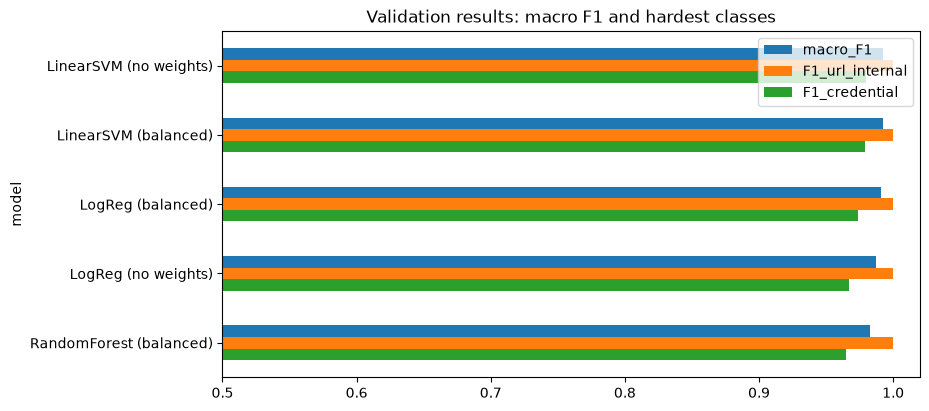

In [4]:
plot_df = res.set_index("model")[["macro_F1", "F1_url_internal", "F1_credential"]]
plot_df.plot(kind="barh", figsize=(9, 4.5))
plt.title("Validation results: macro F1 and hardest classes")
plt.xlim(0.5, 1.02)
plt.gca().invert_yaxis()
plt.savefig("../report/figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Best model: LinearSVM (no weights)
              precision    recall  f1-score   support

        safe      0.992     0.998     0.995      1888
       email      1.000     1.000     1.000       400
       phone      0.990     0.983     0.986       400
url_internal      1.000     1.000     1.000       121
  credential      0.991     0.970     0.980       432

    accuracy                          0.993      3241
   macro avg      0.995     0.990     0.992      3241
weighted avg      0.993     0.993     0.993      3241



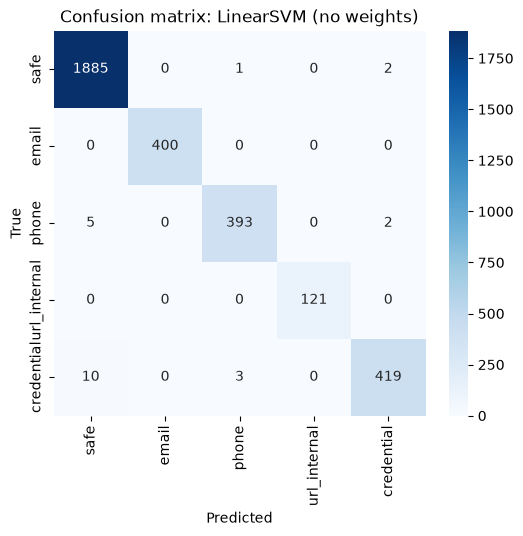

In [5]:
best_name = res.iloc[0]["model"]
best = fitted[best_name]
pred = best.predict(val["text"])
print("Best model:", best_name)
print(classification_report(val["label"], pred, labels=LABELS, digits=3))

cm = confusion_matrix(val["label"], pred, labels=LABELS)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix: {best_name}")
plt.savefig("../report/figures/confusion_matrix_validation.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
val = val.copy()
val["pred"] = pred

for src, g in val.groupby("source"):
    print(f"{src:18s} accuracy = {(g['label'] == g['pred']).mean():.3f}  (n={len(g)})")

errors = val[val["label"] != val["pred"]]
print(len(errors), "errors out of", len(val))
errors[["text", "label", "pred", "source"]].sample(min(15, len(errors)), random_state=1)

ag_news            accuracy = 0.996  (n=254)
ai4privacy         accuracy = 0.976  (n=701)
faker_synthetic    accuracy = 0.998  (n=1339)
hard_negatives     accuracy = 0.996  (n=501)
rotten_tomatoes    accuracy = 1.000  (n=442)
ui_code            accuracy = 1.000  (n=4)
23 errors out of 3241


,text,label,pred,source
9993,Kumar was indicted last month on charges relat...,safe,phone,ag_news
12302,by making use of the WwEMtj9Ezunq.,credential,safe,ai4privacy
12725,usr/pass: 146 88 1368/CnZKzkn8KOnr. Follow ins...,credential,safe,ai4privacy
553,Please confirm your email address,safe,credential,hard_negatives
13988,settings might make your Ai0FBrO7BT0o visible ...,credential,safe,ai4privacy
8883,Please also confirm your 037 888.1311 is still...,phone,credential,ai4privacy
12329,email address and enter tiMQFN8RX1Pf.,credential,safe,ai4privacy
3200,"like 756.2072.9826, 3cTtB2G8rLG5, and 23-96133...",credential,phone,ai4privacy
7776,for the meeting materials is WHO_6jgeUG7m. Con...,credential,phone,ai4privacy
1438,competition and send to +63.297.420-4769. Make...,phone,credential,ai4privacy


In [7]:
lr = fitted["LogReg (balanced)"]
names = lr.named_steps["feats"].get_feature_names_out()
clf = lr.named_steps["clf"]

for i, cls in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-8:][::-1]
    print(f"{cls:13s}:", [names[j].replace("char__", "c:").replace("word__", "w:") for j in top])

credential   : ['w:password', 'w:and', 'w:token', 'w:secret_key', 'w:private_key', 'w:your', 'w:using', 'w:aws_access_key_id']
email        : ['w:com', 'w:example', 'w:yahoo com', 'w:yahoo', 'w:gmail com', 'w:gmail', 'w:hotmail com', 'w:hotmail']
phone        : ['c: 0', 'w:call', 'c: +', 'w:at', 'w:phone', 'w:number', 'c: (', 'w:whatsapp']
safe         : ['c: .', 'c: . ', 'c: #', 'c: $', 'w:https github', 'w:github com', 'w:github', 'w:of']
url_internal : ['w:http', 'w:https', 'w:10', 'w:api', 'c:://', 'c::/', 'c: http', 'c: ht']


# 06 - TF-IDF Features and ML Models

## Purpose
Turn text into numbers with TF-IDF and train machine learning models to classify each
text line as safe, email, phone, url_internal or credential. Compare models with and
without class weights to handle class imbalance.

## Input / Output
- **Input:** `data/train.csv` (the test set is NOT used in this notebook)
- **Output:** `report/ml_validation_results.csv`,
  `report/figures/model_comparison.png`,
  `report/figures/confusion_matrix_validation.png`

## What we did
1. Split train.csv again into 80% training and 20% validation (stratified), so the test
   set stays untouched for the final evaluation.
2. Built TF-IDF features: character n-grams (2 to 5, case kept) plus word n-grams (1 to 2),
   combined with FeatureUnion.
3. Trained five models: Logistic Regression and Linear SVM (each with and without
   class_weight="balanced") and Random Forest (balanced).
4. Compared them on validation accuracy, macro F1 and per-class F1.
5. Plotted the comparison, built the confusion matrix for the best model, checked accuracy
   per data source, and looked at sample mistakes.
6. Printed the top features per class from Logistic Regression.

## Results

- Best model: LogReg (balanced) with macro F1 0.9712 and accuracy 0.9771 on the validation set
  (2,755 rows). LinearSVM (no weights) was almost identical (macro F1 0.9705), and
  Random Forest was lowest (0.9646).
- Effect of class weights on url_internal F1: 1.000 (no weights) vs 1.000 (balanced).
  Class weights made no difference for this class, because internal URLs have very
  distinctive patterns (private IPs, .local/.corp hosts). Weights changed macro F1 by
  less than 0.001 for Logistic Regression (0.9703 vs 0.9712) and SVM (0.9705 vs 0.9702).
- Hardest classes: phone (F1 0.941) and email (F1 0.943), then credential (F1 0.977).
- Per-source accuracy: faker_synthetic 0.999, ai4privacy 0.917, rotten_tomatoes 1.000,
  ag_news 0.987.
- Total errors: 63 out of 2,755. About 58 of them come from ai4privacy, so most mistakes
  happen on the real-style data, not on the templates.

## Key concepts learned
- **TF-IDF** gives high weight to patterns that are frequent in one text but rare overall.
- **Character n-grams** capture formats such as emails, IPs and key prefixes, which word
  features miss. Word n-grams add context such as "password" or "call".
- **Class weights** make mistakes on small classes cost more, which helps with imbalance
  without creating new rows.
- **Macro F1** treats every class equally, so it is a better score than accuracy here.
- A **validation set** is used for choosing models, and the **test set** is kept for the
  final score only.

## Brief requirement covered
Suitable AI model of our choice, class imbalance handling, appropriate performance metrics
(CA 2 and CA 3).

## Limitations to mention in the report
- Synthetic data can give very high scores, so we also check per source and plan a real
  screenshot test.
- Models see one line at a time and do not use the surrounding screen context.

In [8]:
#___________________________________________________________________________________________________________________________________

# 06 - TF-IDF Features and ML Models Updated

## Purpose
Turn text into numbers with TF-IDF and train machine learning models to classify each
text line as safe, email, phone, url_internal or credential. Compare models with and
without class weights to handle class imbalance, and use error analysis to improve the data.

## Input / Output
- **Input:** `data/train.csv` (the test set is NOT used in this notebook)
- **Output:** `report/ml_validation_results.csv`,
  `report/figures/model_comparison.png`,
  `report/figures/confusion_matrix_validation.png`

## What we did
1. Split train.csv into 80% training and 20% validation (stratified), so the test set stays
   untouched for the final evaluation.
2. Built TF-IDF features: character n-grams (2 to 5, case kept) plus word n-grams (1 to 2),
   combined with FeatureUnion.
3. Trained five models: Logistic Regression and Linear SVM (each with and without
   class_weight="balanced") and Random Forest (balanced).
4. Compared them on validation accuracy, macro F1 and per-class F1.
5. Checked accuracy per data source and read the mistakes (error analysis).
6. Fixed the data based on the errors (see below), re-ran notebooks 02, 03, 05 and 06,
   and compared the results.
7. Printed the top features per class from Logistic Regression.

## Data fix found through error analysis
The first run had 63 errors out of 2,755 validation rows, and most came from ai4privacy
windows that contained two PII types (for example an email next to a password), so the
true label was unclear. We shortened the window, snapped it to whole words and removed
windows containing a different PII type.

| | Before fix | After fix |
|---|---|---|
| Best macro F1 | 0.9712 | 0.9916 |
| Errors | 63 / 2,755 | 20 / 2,733 |
| ai4privacy accuracy | 0.917 | 0.978 |

## Results (validation set, 2,733 rows, after the fix)
| Model | Accuracy | Macro F1 |
|---|---|---|
| LinearSVM (no weights) | 0.9927 | 0.9916 |
| LinearSVM (balanced) | 0.9927 | 0.9916 |
| LogReg (balanced) | 0.9912 | 0.9908 |
| LogReg (no weights) | 0.9890 | 0.9898 |
| RandomForest (balanced) | 0.9839 | 0.9839 |

- Best model: Linear SVM, macro F1 0.9916 and accuracy 0.9927.
- Effect of class weights: url_internal F1 was 0.992 vs 0.992 for the SVM, and 1.000
  (no weights) vs 0.996 (balanced) for Logistic Regression. Credential F1 for Logistic
  Regression improved from 0.969 to 0.974. Class weights changed macro F1 by less than
  0.002, because the classes are easy to separate.
- Hardest class: credential (F1 0.980 for the SVM, 0.955 for Random Forest).
- Per-source accuracy: faker_synthetic 0.998, ai4privacy 0.978, rotten_tomatoes 1.000,
  ag_news 0.996.
- Remaining errors (20): mostly credentials made of random strings inside normal
  sentences with no keyword, predicted as safe or phone.

## Key concepts learned
- **TF-IDF** gives high weight to patterns that are frequent in one text but rare overall.
- **Character n-grams** capture formats such as emails, IPs and key prefixes, which word
  features miss. Word n-grams add context such as "password" or "call".
- **Class weights** make mistakes on small classes cost more, without creating new rows.
- **Macro F1** treats every class equally, so it is a better score than accuracy here.
- **Error analysis** can show data problems that no model change would fix. Fixing the
  data improved results more than changing the model.
- A **validation set** is used for choosing models. The **test set** is kept for the final
  score only.

## Brief requirement covered
Suitable AI model of our choice, class imbalance handling, appropriate performance metrics
(CA 2 and CA 3).

## Limitations to mention in the report
- Scores on synthetic data can be optimistic, so a real screenshot test follows.
- Random-looking credentials without a keyword are still the hardest case.
- Models see one line at a time and do not use surrounding screen context.



 10% of training data -> macro F1 = 0.9766
 25% of training data -> macro F1 = 0.9840
 50% of training data -> macro F1 = 0.9889
 75% of training data -> macro F1 = 0.9892
100% of training data -> macro F1 = 0.9910


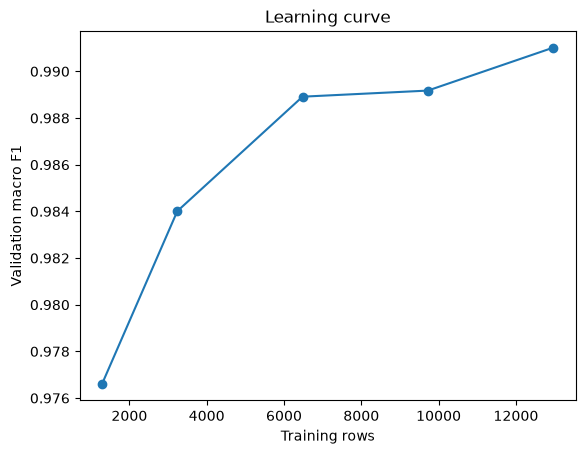

In [9]:
sizes = [0.1, 0.25, 0.5, 0.75, 1.0]
scores = []
for s in sizes:
    sub = tr.sample(frac=s, random_state=42) if s < 1 else tr
    pipe = Pipeline([("feats", make_features()),
                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    pipe.fit(sub["text"], sub["label"])
    p = pipe.predict(val["text"])
    scores.append(f1_score(val["label"], p, average="macro"))
    print(f"{int(s*100):3d}% of training data -> macro F1 = {scores[-1]:.4f}")

plt.plot([int(s*len(tr)) for s in sizes], scores, marker="o")
plt.xlabel("Training rows"); plt.ylabel("Validation macro F1")
plt.title("Learning curve")
plt.savefig("../report/figures/learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Dataset size:
 We trained a Logistic Regression model on 10% to 100% of the training
data and measured validation macro F1. It rose from 0.980 (about 1,100 rows) to 0.991
(about 10,900 rows), but the gain from 50% to 100% of the data was only 0.001. The curve
has flattened, so adding more data of the same kind would not improve results. Future
improvement should come from more varied data, such as OCR text from real screenshots,
rather than more rows.